<a href="https://colab.research.google.com/github/Krishna62186/Customer-Segmentation-/blob/main/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()          # choose Test.csv
df = pd.read_csv("Test.csv")
print(df.shape)
df.head()

Saving Test.csv to Test (1).csv
(2627, 10)


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6


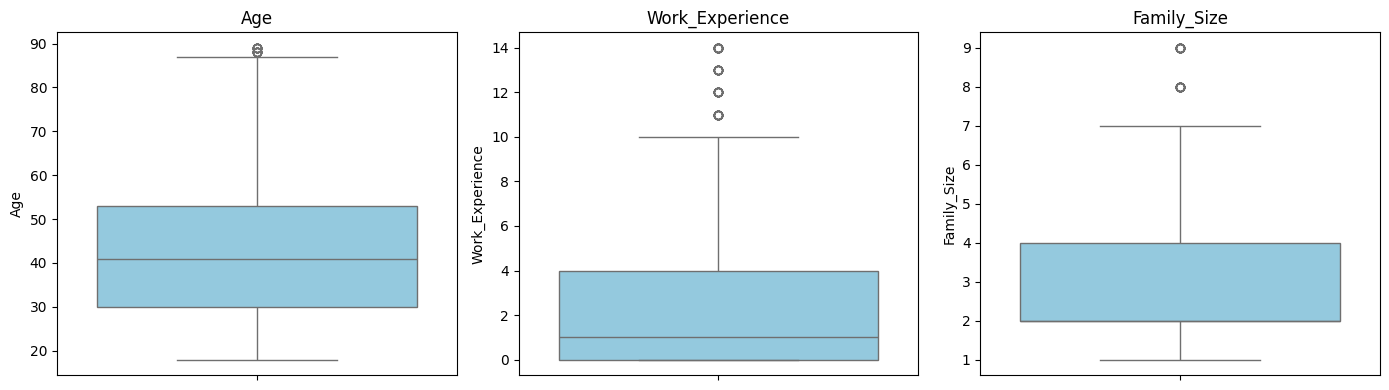

Age: 19 outliers (valid range -4.5 to 87.5)
Work_Experience: 58 outliers (valid range -6.0 to 10.0)
Family_Size: 31 outliers (valid range -1.0 to 7.0)


In [8]:
import seaborn as sns

raw_num = ["Age", "Work_Experience", "Family_Size"]

# Box plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, raw_num):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(c)
plt.tight_layout()
plt.show()

# Count outliers using the IQR rule
for c in raw_num:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"{c}: {n} outliers (valid range {lo:.1f} to {hi:.1f})")

In [2]:
from sklearn.preprocessing import StandardScaler

data = df.drop(columns=["ID"]).copy()

num_cols = ["Age", "Work_Experience", "Family_Size"]
cat_cols = ["Gender", "Ever_Married", "Graduated", "Profession", "Spending_Score", "Var_1"]

# Fill missing values
for c in num_cols:
    data[c] = data[c].fillna(data[c].median())
for c in cat_cols:
    data[c] = data[c].fillna(data[c].mode()[0])

# Spending_Score is ordinal, so map it to numbers
data["Spending_Score"] = data["Spending_Score"].map({"Low": 0, "Average": 1, "High": 2})
cat_cols.remove("Spending_Score")

# One-hot encode the remaining categoricals
X = pd.get_dummies(data, columns=cat_cols, drop_first=True)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

(2627, 21)


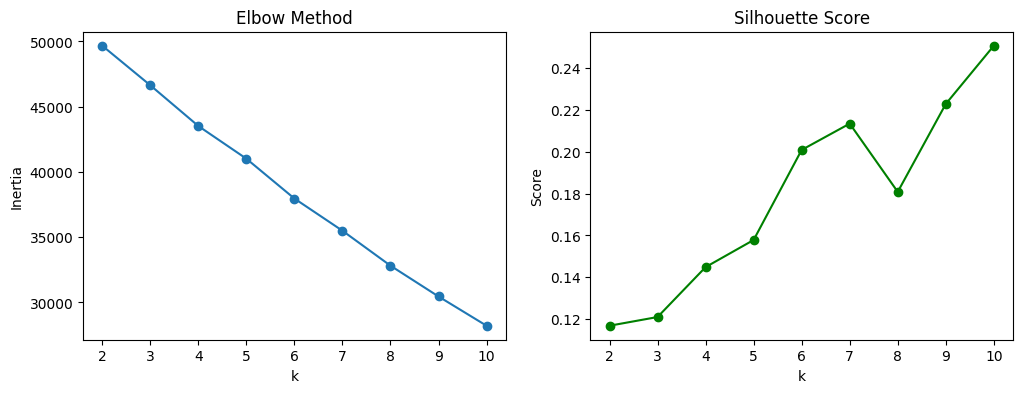

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sil_scores = [], []
K = range(2, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertias, "o-")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")

ax[1].plot(K, sil_scores, "o-", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Score")
plt.show()

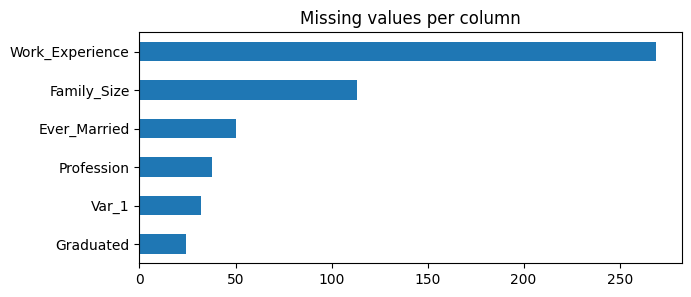

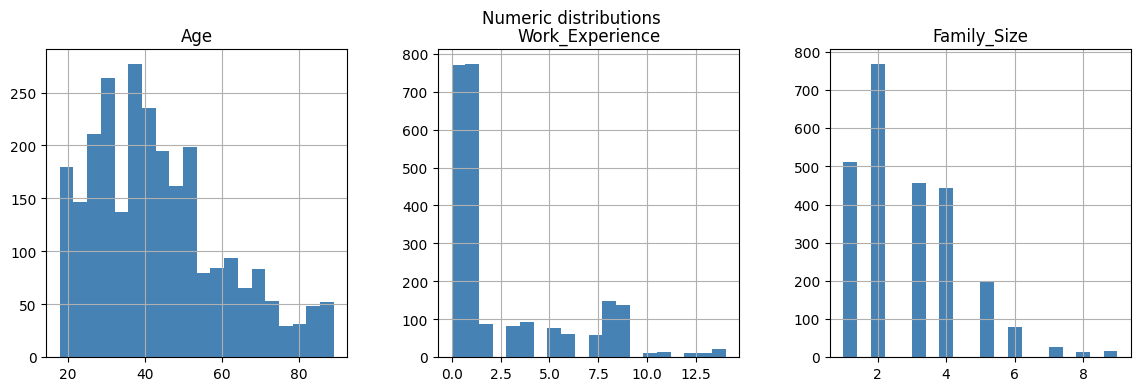

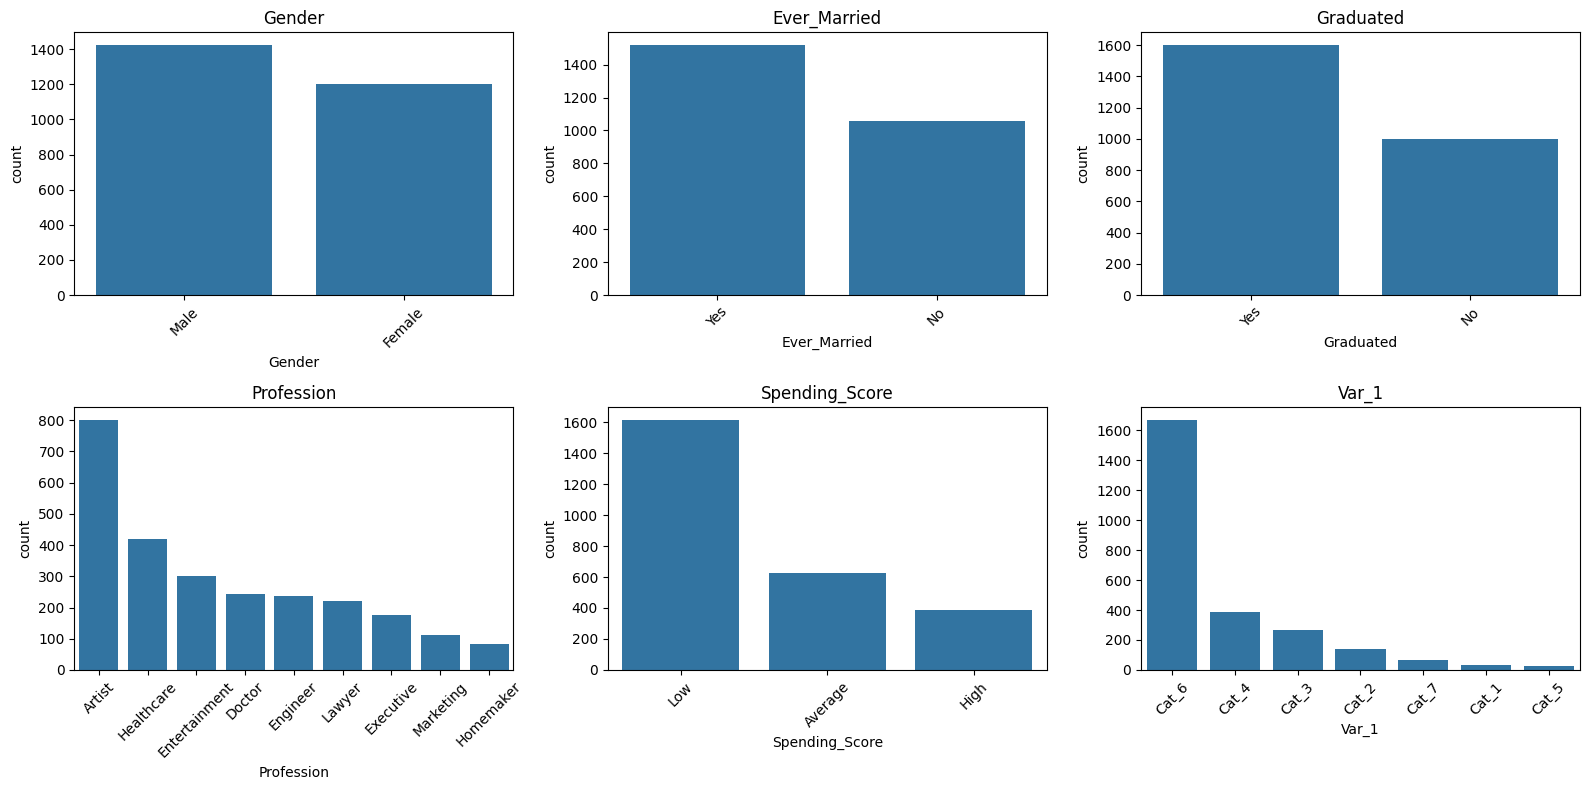

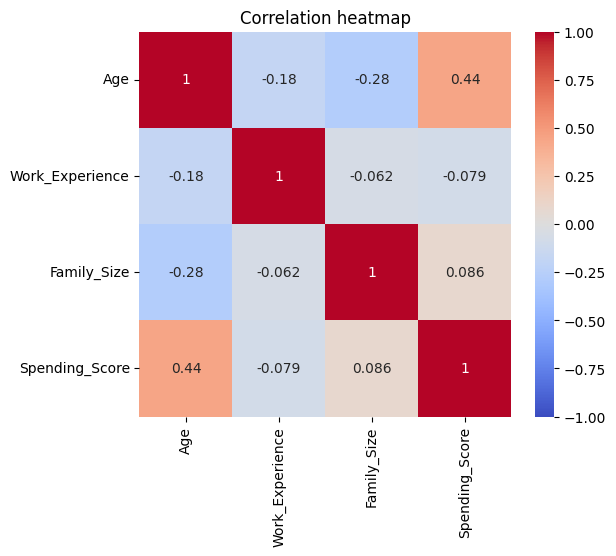

In [9]:
# 1. Missing values
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()
missing.plot(kind="barh", figsize=(7, 3), title="Missing values per column")
plt.show()

# 2. Histograms of numeric columns
df[raw_num].hist(bins=20, figsize=(14, 4), layout=(1, 3), color="steelblue")
plt.suptitle("Numeric distributions")
plt.show()

# 3. Count plots of categorical columns
cat_raw = ["Gender", "Ever_Married", "Graduated", "Profession", "Spending_Score", "Var_1"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cat_raw):
    sns.countplot(x=df[c], ax=ax, order=df[c].value_counts().index)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# 4. Correlation heatmap (numeric + ordinal Spending_Score)
corr = data[["Age", "Work_Experience", "Family_Size", "Spending_Score"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

In [4]:
k = 4   # <-- set this from the elbow / silhouette plots

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Silhouette score:", silhouette_score(X_scaled, df["Cluster"]))
print(df["Cluster"].value_counts().sort_index())

Silhouette score: 0.14488878027656676
Cluster
0    1142
1     834
2     384
3     267
Name: count, dtype: int64


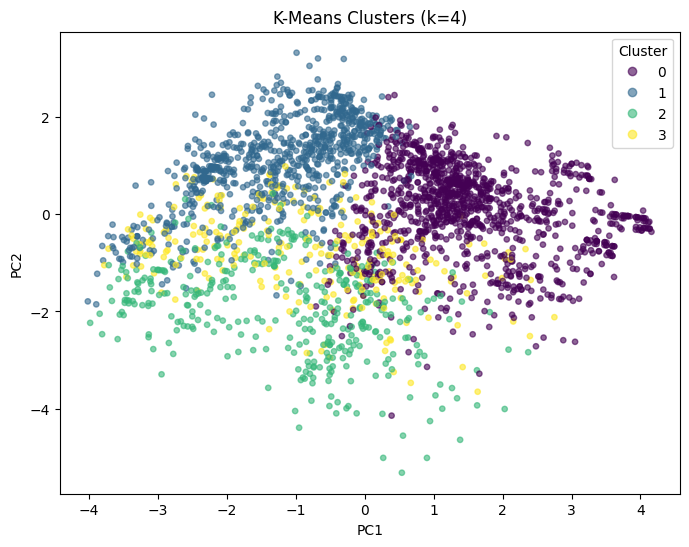

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis", alpha=0.6, s=15)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"K-Means Clusters (k={k})")
plt.show()

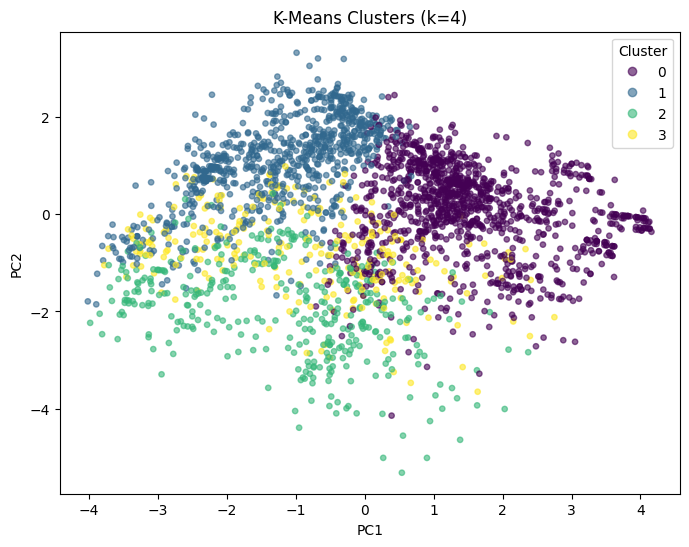

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis", alpha=0.6, s=15)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"K-Means Clusters (k={k})")
plt.show()

In [7]:
# Numeric summary per cluster
print(df.groupby("Cluster")[["Age", "Work_Experience", "Family_Size"]].mean().round(2))

# Categorical breakdown per cluster
for c in ["Gender", "Ever_Married", "Graduated", "Profession", "Spending_Score"]:
    print(f"\n{c}")
    print(pd.crosstab(df["Cluster"], df[c], normalize="index").round(2))

           Age  Work_Experience  Family_Size
Cluster                                     
0        54.78             2.11         2.55
1        31.85             3.30         2.84
2        38.99             2.17         3.55
3        39.61             2.64         2.93

Gender
Gender   Female  Male
Cluster              
0          0.39  0.61
1          0.54  0.46
2          0.48  0.52
3          0.48  0.52

Ever_Married
Ever_Married    No   Yes
Cluster                 
0             0.01  0.99
1             0.92  0.08
2             0.44  0.56
3             0.47  0.53

Graduated
Graduated    No   Yes
Cluster              
0          0.24  0.76
1          0.46  0.54
2          0.61  0.39
3          0.46  0.54

Profession
Profession  Artist  Doctor  Engineer  Entertainment  Executive  Healthcare  \
Cluster                                                                      
0             0.41    0.07      0.06           0.12       0.12        0.01   
1             0.26    0.12      0.07 

,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
k,,,
2,0.117,2.830,290.146
3,0.121,2.482,239.715
4,0.145,2.311,233.900
5,0.158,2.374,226.127
6,0.201,1.866,237.535
7,0.213,1.838,242.006
8,0.181,1.699,254.825
9,0.223,1.619,265.532
10,0.251,1.471,277.797


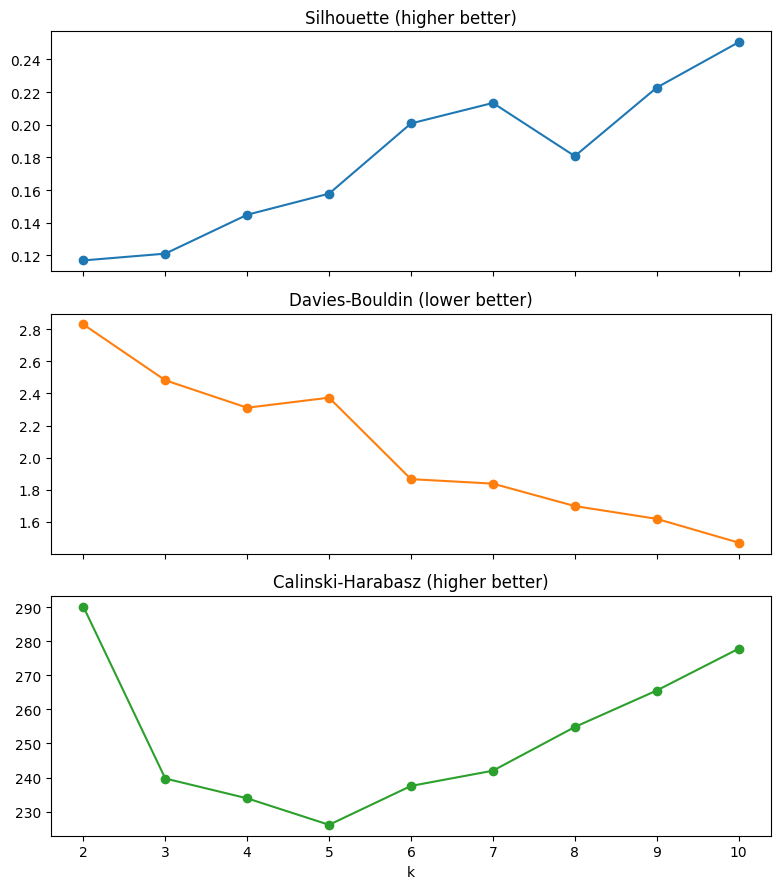


Final model (k=4)
Silhouette:         0.145
Davies-Bouldin:     2.311
Calinski-Harabasz:  233.9


In [10]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import KMeans

rows = []
for kk in range(2, 11):
    lab = KMeans(n_clusters=kk, random_state=42, n_init=10).fit_predict(X_scaled)
    rows.append({
        "k": kk,
        "Silhouette (higher better)": silhouette_score(X_scaled, lab),
        "Davies-Bouldin (lower better)": davies_bouldin_score(X_scaled, lab),
        "Calinski-Harabasz (higher better)": calinski_harabasz_score(X_scaled, lab),
    })
metrics = pd.DataFrame(rows).set_index("k")
display(metrics.round(3))

metrics.plot(subplots=True, figsize=(8, 9), marker="o", legend=False,
             title=list(metrics.columns))
plt.tight_layout()
plt.show()

# Scores for your chosen k
print(f"\nFinal model (k={k})")
print("Silhouette:        ", round(silhouette_score(X_scaled, df['Cluster']), 3))
print("Davies-Bouldin:    ", round(davies_bouldin_score(X_scaled, df['Cluster']), 3))
print("Calinski-Harabasz: ", round(calinski_harabasz_score(X_scaled, df['Cluster']), 1))

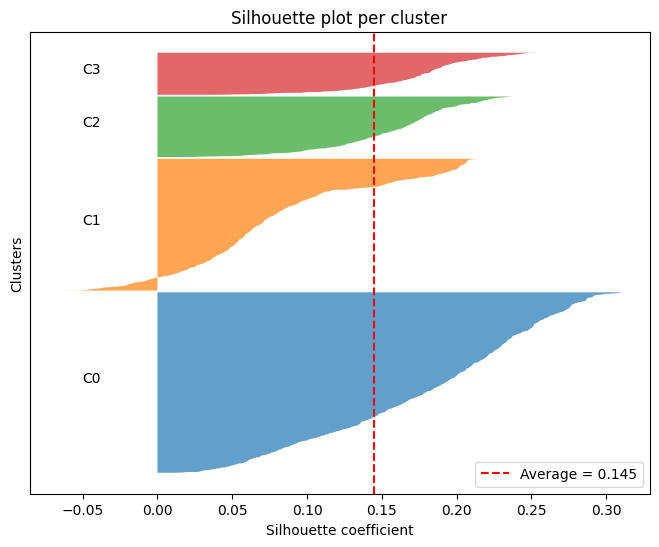

% of points with negative silhouette per cluster:
0     0.0
1    10.1
2     0.0
3     0.0
dtype: float64


In [11]:
from sklearn.metrics import silhouette_samples

labels = df["Cluster"].values
sil_vals = silhouette_samples(X_scaled, labels)
avg_sil = sil_vals.mean()

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for i in range(k):
    v = np.sort(sil_vals[labels == i])
    y_upper = y_lower + len(v)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, v, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * len(v), f"C{i}")
    y_lower = y_upper + 10

ax.axvline(avg_sil, color="red", linestyle="--", label=f"Average = {avg_sil:.3f}")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Clusters")
ax.set_yticks([])
ax.legend()
ax.set_title("Silhouette plot per cluster")
plt.show()

# % of poorly assigned points (negative silhouette) per cluster
neg = pd.Series(sil_vals < 0).groupby(labels).mean().mul(100).round(1)
print("% of points with negative silhouette per cluster:")
print(neg)

In [12]:
from sklearn.metrics import adjusted_rand_score

base = df["Cluster"].values

# (a) Different random seeds
ari_seeds = []
for seed in range(1, 11):
    lab = KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(X_scaled)
    ari_seeds.append(adjusted_rand_score(base, lab))

# (b) 80% subsamples
rng = np.random.RandomState(0)
ari_sub = []
for i in range(10):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    km = KMeans(n_clusters=k, random_state=i, n_init=10).fit(X_scaled[idx])
    ari_sub.append(adjusted_rand_score(base, km.predict(X_scaled)))

print(f"Different seeds  - mean ARI: {np.mean(ari_seeds):.3f} (min {np.min(ari_seeds):.3f})")
print(f"80% subsamples   - mean ARI: {np.mean(ari_sub):.3f} (min {np.min(ari_sub):.3f})")
print("\nARI close to 1 = very stable, above ~0.8 = good, below ~0.5 = unstable clusters")

Different seeds  - mean ARI: 0.441 (min 0.106)
80% subsamples   - mean ARI: 0.315 (min 0.154)

ARI close to 1 = very stable, above ~0.8 = good, below ~0.5 = unstable clusters


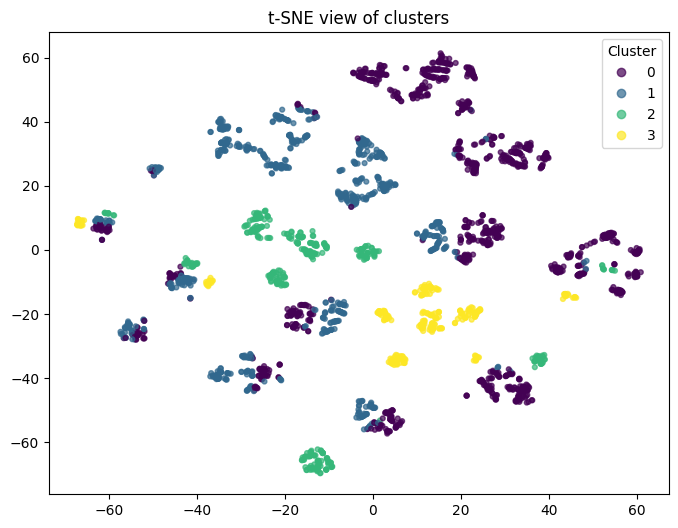

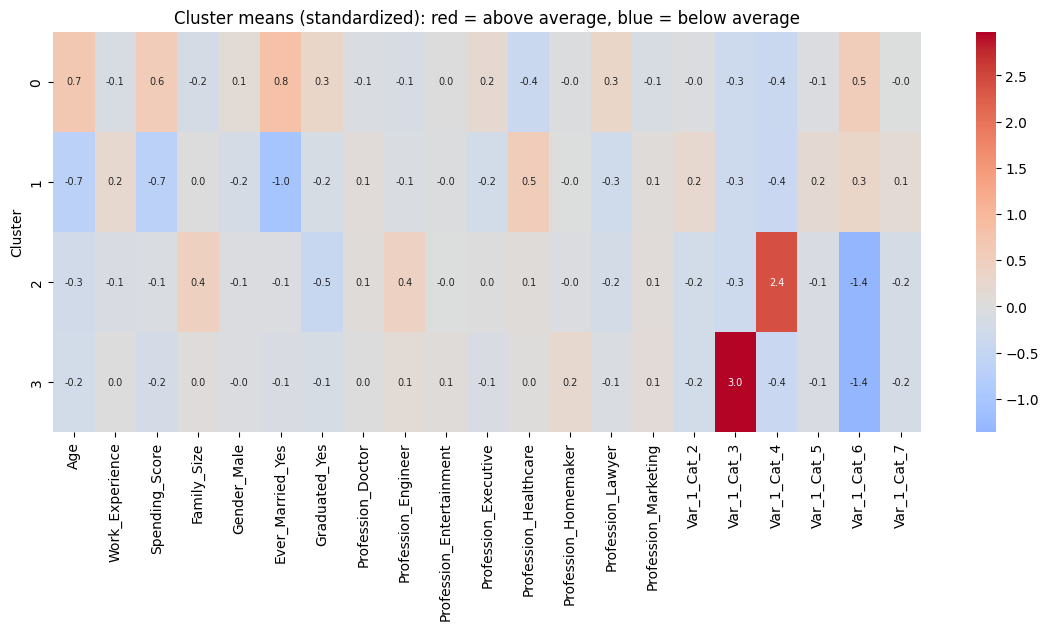

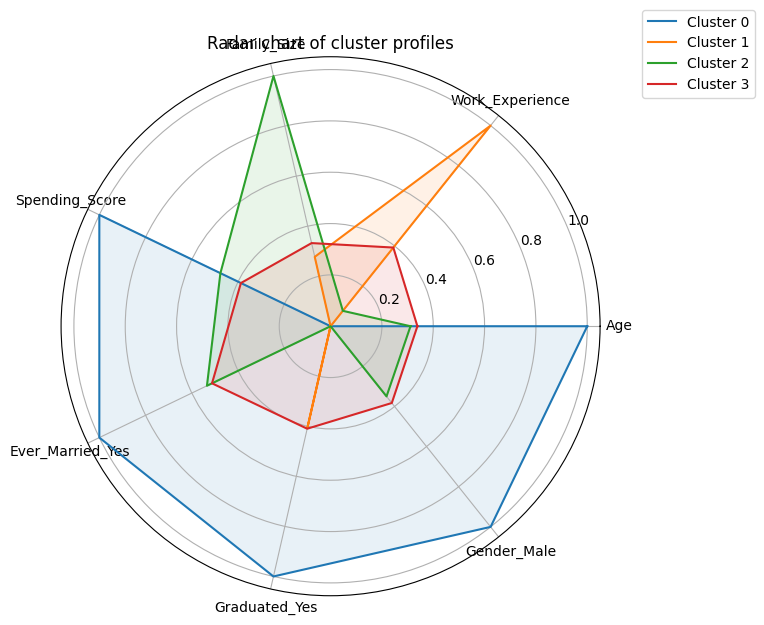

In [13]:
from sklearn.manifold import TSNE

# --- t-SNE ---
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca")
tsne_coords = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sc = plt.scatter(tsne_coords[:, 0], tsne_coords[:, 1], c=df["Cluster"], cmap="viridis", s=12, alpha=0.7)
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("t-SNE view of clusters")
plt.show()

# --- Heatmap of cluster means (scaled features) ---
X_df = pd.DataFrame(X_scaled, columns=X.columns)
cluster_means = X_df.groupby(df["Cluster"].values).mean()

plt.figure(figsize=(14, 4 + 0.3 * k))
sns.heatmap(cluster_means, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Cluster means (standardized): red = above average, blue = below average")
plt.ylabel("Cluster")
plt.show()

# --- Radar chart ---
radar_cols = [c for c in ["Age", "Work_Experience", "Family_Size", "Spending_Score",
                          "Ever_Married_Yes", "Graduated_Yes", "Gender_Male"] if c in X.columns]
means = X.groupby(df["Cluster"].values)[radar_cols].mean()
means = (means - means.min()) / (means.max() - means.min() + 1e-9)   # scale 0-1 for plotting

angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for cl in means.index:
    vals = means.loc[cl].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, label=f"Cluster {cl}")
    ax.fill(angles, vals, alpha=0.1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_cols)
ax.set_title("Radar chart of cluster profiles")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()

In [14]:
# Profile table
profile = df.groupby("Cluster").agg(
    Size=("ID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Work_Exp=("Work_Experience", "mean"),
    Avg_Family=("Family_Size", "mean"),
).round(1)
profile["Top_Profession"] = df.groupby("Cluster")["Profession"].agg(lambda s: s.mode()[0])
profile["Top_Spending"] = df.groupby("Cluster")["Spending_Score"].agg(lambda s: s.mode()[0])
profile["Married_%"] = df.groupby("Cluster")["Ever_Married"].apply(lambda s: (s == "Yes").mean() * 100).round(0)
profile["Graduated_%"] = df.groupby("Cluster")["Graduated"].apply(lambda s: (s == "Yes").mean() * 100).round(0)

# Auto-generated starter names
def age_group(a):
    return "Young" if a < 35 else ("Middle-aged" if a < 55 else "Senior")

profile["Auto_Name"] = [
    f"{age_group(r.Avg_Age)} {r.Top_Spending}-spenders" for r in profile.itertuples()
]
display(profile)

# Edit these manually after reading the table above
personas = {
    # 0: ("Young low spenders", "Offer discounts and entry-level products"),
    # 1: ("Senior high spenders", "Target with premium and loyalty offers"),
}

df["Persona"] = df["Cluster"].map(lambda c: personas.get(c, (profile.loc[c, "Auto_Name"], ""))[0])
print(df.groupby(["Cluster", "Persona"]).size())

,Size,Avg_Age,Avg_Work_Exp,Avg_Family,Top_Profession,Top_Spending,Married_%,Graduated_%,Auto_Name
Cluster,,,,,,,,,
0,1142,54.8,2.1,2.6,Artist,Average,97.0,76.0,Middle-aged Average-spenders
1,834,31.9,3.3,2.8,Healthcare,Low,8.0,54.0,Young Low-spenders
2,384,39.0,2.2,3.6,Engineer,Low,54.0,39.0,Middle-aged Low-spenders
3,267,39.6,2.6,2.9,Artist,Low,51.0,53.0,Middle-aged Low-spenders


Cluster  Persona                     
0        Middle-aged Average-spenders    1142
1        Young Low-spenders               834
2        Middle-aged Low-spenders         384
3        Middle-aged Low-spenders         267
dtype: int64
